<h1><center> Analyse et Décomposition d'une Série Temporelle

On veut simuler et analyser le trafic mensuel d'un site web sur les 5 dernières années (soit 60 mois) pour identifier ses composantes cachées.

## 1. Génération de la série temporelle

In [28]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt


In [29]:
np.random.seed(42)

In [30]:
#  Définir les valeurs
n = 60 # 60 MOIS --> 5 ans
time = np.arange(n)  # liste de [ 0, 1, ........ 59]

In [31]:
# 1. Création d'un index temporel mensuel sur 5 ans ( de janvier 2021 à décembre 2025)
dates = pd.date_range(start="2021-01-01", periods=n, freq="MS")


# 2. Génération d'une série de 60 valeurs contenant:
# A- Une tendance linéaire en augmentation
trend = 0.5* time + 20

# B- une saisonaité annuelle
saisonalite = 4 * np.sin(2* np.pi * time /12) # Saisonnalité annuelle (période = 12)

# C- un bruit blanc aléatoire 
white_noise = np.random.normal(loc=0, scale=1, size=n)  # Bruit blanc gaussien

# Combinaison additive
series = trend + saisonalite + white_noise


# 3. Série temporelle finale 
df = pd.DataFrame(
    {
        "Traffic": series,
    },
    index = dates
)

print(df[:5])



              Traffic
2021-01-01  20.496714
2021-02-01  22.361736
2021-03-01  25.111790
2021-04-01  27.023030
2021-05-01  25.229948


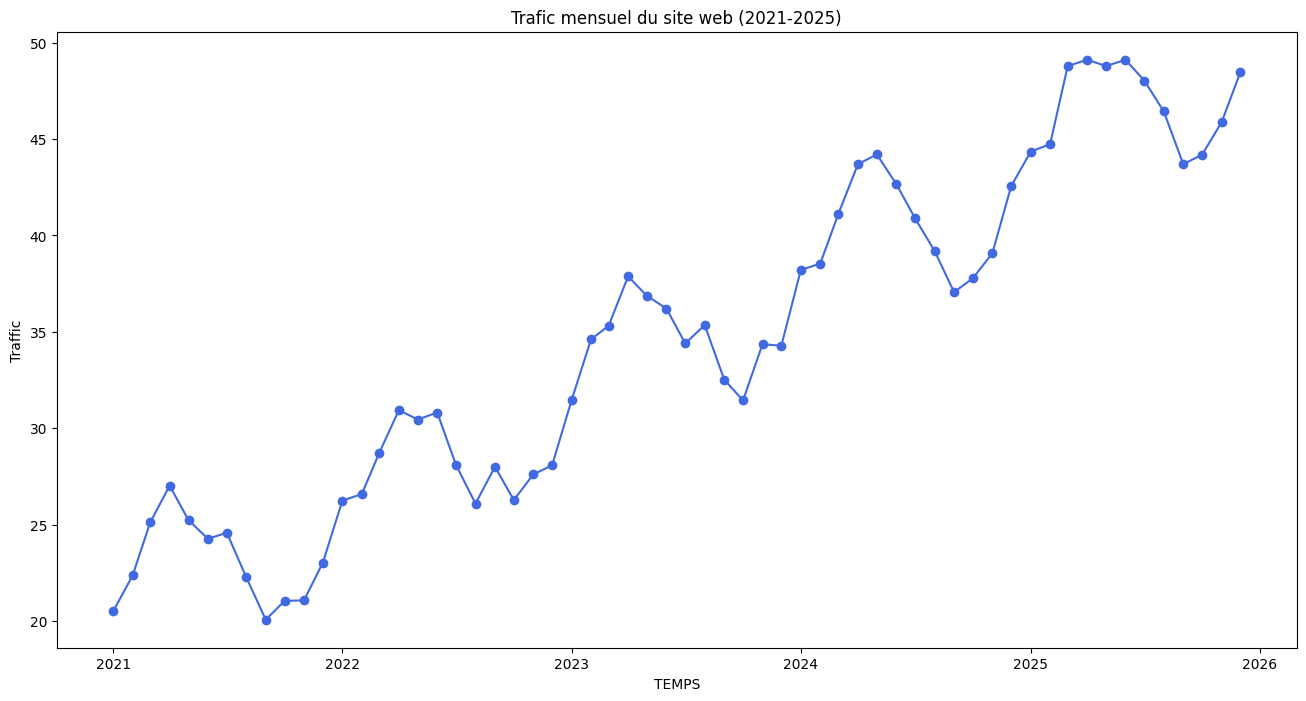

In [32]:
# Visualisation de la série temporelle brute

plt.figure(figsize=(16,8))
plt.plot(df.index, df['Traffic'], label="Série brute", color="royalblue", marker = "o")
plt.xlabel("TEMPS")
plt.ylabel("Traffic")
plt.title("Trafic mensuel du site web (2021-2025)")
plt.show()

### 2. Décomposition de la série temporelle en Tendance, Saisonalité, Résidus

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

# On utilise seasonal_decompose car a série a une saisonalité à période fixe et rigide dans ce cas exactement 12 mois por une année

Il existe d'autres fonctions de décomposition comme:
- statsmodels.tsa.seasonal.STL : gére mieux mes valeurs abérantes
- MSTL : Très utilse si la série a plusieurs saisonalités en meme temps(Par exemple: un trafic web qui a une saisonnalité journalière ET hebdomadaire ET annuelle)

In [56]:
decomposition = seasonal_decompose(df['Traffic'], model= "additive", period = 12)



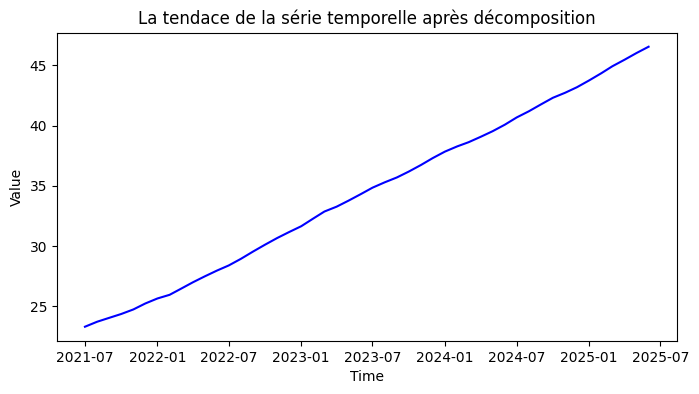

In [45]:
# Tendance
trend = decomposition.trend

plt.figure(figsize=(8,4))
plt.plot(df.index, trend, label="Tendance de la série temporelle", color="blue")
plt.xlabel("Time")
plt.ylabel("Value")
plt.title("La tendace de la série temporelle après décomposition")
plt.show()


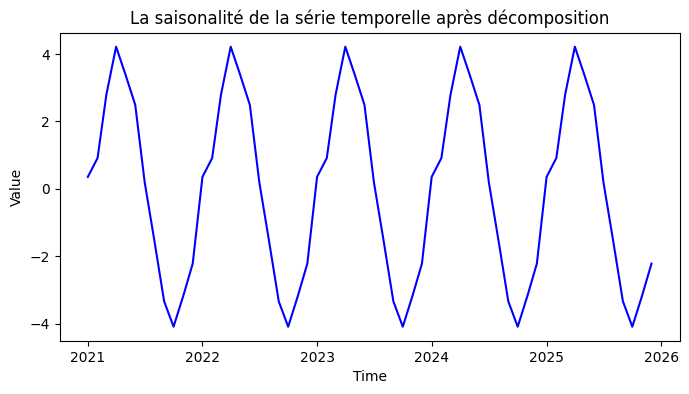

In [46]:
# Saisonalité
saison = decomposition.seasonal


plt.figure(figsize=(8,4))
plt.plot(df.index, saison, label="La saisonalité de la série temporelle", color="blue")
plt.xlabel("Time")
plt.ylabel("Value")
plt.title("La saisonalité de la série temporelle après décomposition")
plt.show()




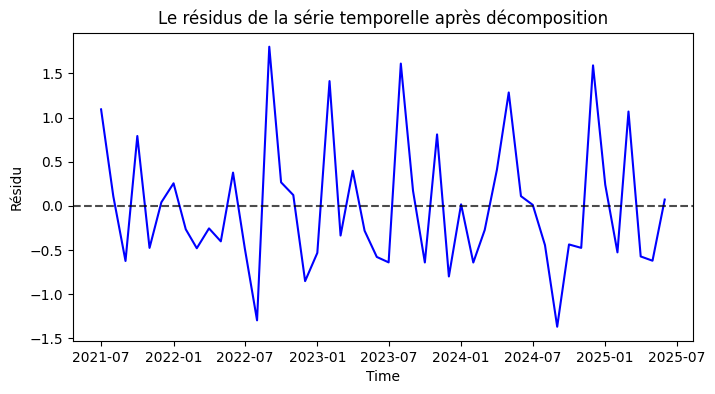

In [54]:
# Résidus
residus = decomposition.resid

plt.figure(figsize=(8,4))
plt.plot(df.index, residus, label="Le résidus de la série temporelle", color="blue")
plt.axhline(0, color="black", linestyle="--", alpha=0.7)
plt.xlabel("Time")
plt.ylabel("Résidu")
plt.title("Le résidus de la série temporelle après décomposition")
plt.show()

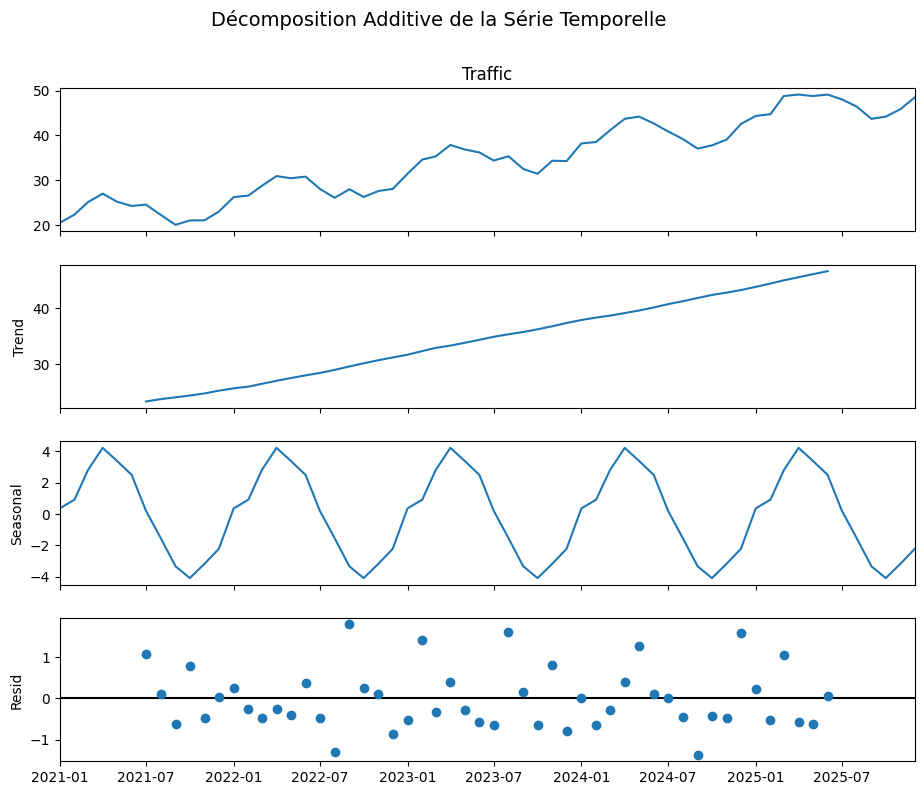

In [55]:
# CODE PLUS SIMPLE QUI AFFICHE LES 3
fig = decomposition.plot()
fig.set_size_inches(10, 8)
plt.suptitle("Décomposition Additive de la Série Temporelle", fontsize=14, y=1.02)
plt.show()